# import function helper from workload_data_loader

In [36]:
import numpy as np
import time

def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility
        scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource
        consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware
        capacity limits (b_i).
    """
    
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
    
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        # Maximum hardware capacity limits (length m)
        capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    return n, m, utilities, demands, capacities

if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m) : {m}")
        print(f"Utility scores shape (p_j) : {utilities.shape}")
        print(f"Resource demands shape (r_ij) : {demands.shape}")
        print(f"Utility scores shape (p_j) : {utilities}")
        print(f"Resource demands shape (r_ij) : {demands}")
        print(f"Capacity limits (b_i) : {capacities}")
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 90
Number of resource bounds (m) : 5
Utility scores shape (p_j) : (90,)
Resource demands shape (r_ij) : (5, 90)
Utility scores shape (p_j) : [360.  83.  59. 130. 431.  67. 230.  52.  93. 125. 670. 892. 600.  38.
  48. 147.  78. 256.  63.  17. 120. 164. 432.  35.  92. 110.  22.  42.
  50. 323. 514.  28.  87.  73.  78.  15.  26.  78. 210.  36.  85. 189.
 274.  43.  33.  10.  19. 389. 276. 312.  94.  68.  73. 192.  41. 163.
  16.  40. 195. 138.  73. 152. 400.  26.  14. 170. 205.  57. 369. 435.
 123.  25.  94.  88.  90. 146.  55.  29.  82.  74. 100.  72.  31.  29.
 316. 244.  70.  82.  90.  52.]
Resource demands shape (r_ij) : [[ 7.  0. 30. 22. 80. 94. 11. 81. 70. 64. 59. 18.  0. 36.  3.  8. 15. 42.
   9.  0. 42. 47. 52. 32. 26. 48. 55.  6. 29. 84.  2.  4. 18. 56.  7. 29.
  93. 44. 71.  3. 86. 66. 31. 65.  0. 79. 20. 65. 52. 13. 48. 14.  5. 72.
  14. 39. 46. 27. 11. 91. 15. 25.  0. 94. 53. 48. 27. 99.  6. 17. 69. 43.
   0. 

In [37]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m) : {m}")
        print(f"Utility scores shape (p_j) : {utilities.shape}")
        print(f"Resource demands shape (r_ij) : {demands.shape}")
        print(f"Utility scores shape (p_j) : {utilities}")
        print(f"Resource demands shape (r_ij) : {demands}")
        print(f"Capacity limits (b_i) : {capacities}")
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m) : 2
Utility scores shape (p_j) : (28,)
Resource demands shape (r_ij) : (2, 28)
Utility scores shape (p_j) : [ 1898.   440. 22507.   270. 14148.  3100.  4650. 30800.   615.  4975.
  1160.  4225.   510. 11880.   479.   440.   490.   330.   110.   560.
 24355.  2885. 11748.  4550.   750.  3720.  1950. 10500.]
Resource demands shape (r_ij) : [[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]
Capacity limits (b_i) : [500. 500.]


## Baseline Function

**Design choice.** The solution is encoded into a binary vector `x` of length *n* (1 = deploy the model, 0 = skip it). The function `TungTungSahur` chose random chosen number between 0 and 1 for every devices, then it calculate total utility `utilities @ x` and the usage of each resource `demands @ x` of chosen devices . Then we use `SahurOrAssasino` to evaluate to chose new best result if every resource total is within its capacity and its utility score of chosen once is higher than the best so far. The function `lol` is the function to run both of the function in 6766 steps and return best result and run log so far

**Strength:** The baseline function is the easiest way to solve the problem by giving a best result so that new chosen must have valid storage higher score to become new best which make the functions easy to setup and have a major advantages if required fast but not most utilised result

**Weakness:** A random vector contains about half of all models. On the n90 instance, total demand is far above capacity on every resource (resource 2 is roughly 3x over), so almost every random candidate is infeasible and wasted. The search only keeps the rare ones that happen to fit

**Results (single run, seed 42).**

| Instance | Best utility | Resource usage / capacity |
|---|---|---|
| n28, m2 | 123,677 | 470 / 500, 477 / 500 |

In [38]:
import matplotlib.pyplot as plt
import random
np.random.seed(42)

def TungTungSahur(utilities, demands):
    result=np.random.randint(0,2,size=len(utilities))
    brainrot=utilities @ result
    brain_cap=demands @ result
    return brainrot,brain_cap,result

def SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=None):
    if np.all(brain_cap <= capacities) and brainrot>bestie:
        bestie = brainrot
        bestie_res = result

    return bestie,bestie_res
    
def lol(n, m, utilities, demands, capacities):
    log=[]
    for lol in range(1, 6767):
        brainrot,brain_cap,result= TungTungSahur(utilities, demands)
        if lol==1:
            bestie,bestie_res =SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=np.zeros(n, dtype=int))
        else:
            bestie,bestie_res =SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=bestie,bestie_res=bestie_res)
            
        log.append({'lol':lol,'score':bestie})
        
    return bestie,bestie_res,log

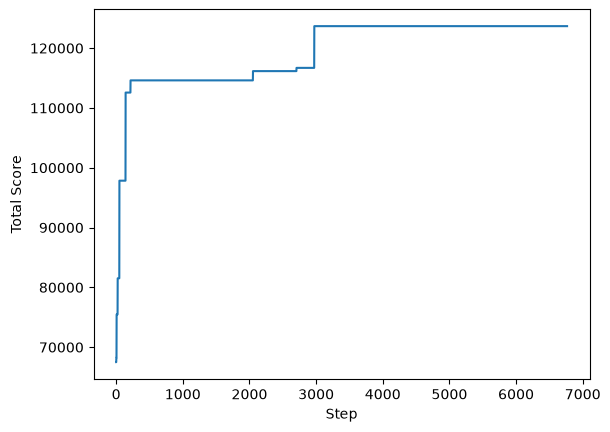

123677.0
[0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 1 0]
[470. 477.]


In [39]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=lol(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

## Hill climber repair function

**Design choice:** The new hill climber function `CapuchinoAssassino` take the idea from the paper [Chu & Beasley (1998), "A Genetic Algorithm for the Multidimensional Knapsack Problem", Journal of Heuristics 4, pp. 63-86.](https://link.springer.com/article/10.1023/A:1009642405419#citeas) to repair and keep best utility:

1. **Pick model:** instead of fully random choices, now only pick 1 model to change
2. **Calculate Efficiency of chosen model** `eff_j = utility_j / sum_i (demand_ij / capacity_i)`. Dividing each demand by its capacity puts all resources on the same scale, so a model that uses a lot of a scarce resource is penalised more. If a model have higher efficiency the more utility it will have per capacity
3. **Remove unefficience model:** Remove models that have least efficience score if exceed capacity untill it reaches belowed max capacity
4. **Keep chosen model:** Keep models that have most efficience score and add untill before it reached max capacity

The function `SahurOrAssasino2` only compares utilities scores if it better than best because the `CapuchinoAssassino` function already remove models to reach below the max capacity. And `league_of_legends` the same as the `lol` functions wirh 6766 steps

**Why this function better than baseline random function:** the baseline random functions wasted the chosen design because even if it might violates the rule of not picking more than max capacity, it might have picked efficiency model that uses fewest capacity but still have high utility score. And this design fix that problem by calculate efficiency of each model and only pick best efficience model untill it reached below the max capacity resource and the calculate efficiency function can act like a penalty function that give lower score if it not efficience model

**Weakness:** this function in single run with the same number steps can took longer time to complete although it can reach better result in the first few steps

**Results (single run, seed 42).**

| Instance | Best utility | Resource usage / capacity |
|---|---|---|
| n90, m5 | 10,844 | 1499 / 2100, 1096 / 1100, 1799 / 3300, 1700 / 3700, 2151 / 3600 |

In [43]:
def CapuchinoAssassino(utilities, demands, capacities, current=None):
    if current is None:
        result=np.random.randint(0,2,size=len(utilities))
    else:
        result=current.copy()
        j=np.random.randint(len(utilities))
        result[j]=1-result[j]
    usage=demands @ result
    
    if not np.all(usage <= capacities):
        eff=utilities/((demands/capacities[:,None]).sum(axis=0)+1e-9)
        order=np.argsort(-eff)
        for k in order[::-1]:
            if np.all(usage <= capacities):
                break
            if result[k]==1:
                result[k]=0
                usage=usage-demands[:,k]
        for k in order:
            if result[k]==0 and np.all(usage+demands[:,k] <= capacities):
                result[k]=1
                usage=usage+demands[:,k]
    brainrot=utilities @ result
    brain_cap=demands @ result
    return brainrot,brain_cap,result

def SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=None):
    if brainrot>=bestie:
        bestie = brainrot
        bestie_res = result

    return bestie,bestie_res
    
def league_of_legends(n, m, utilities, demands, capacities):
    log=[]
    for lol in range(1, 6767):
        if lol==1:
            brainrot,brain_cap,result= CapuchinoAssassino(utilities, demands,capacities)
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=np.zeros(n, dtype=int))
        else:
            brainrot,brain_cap,result= CapuchinoAssassino(utilities, demands,capacities,current=bestie_res)
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=bestie,bestie_res=bestie_res)
            
        log.append({'lol':lol,'score':bestie})
    
    return bestie,bestie_res,log

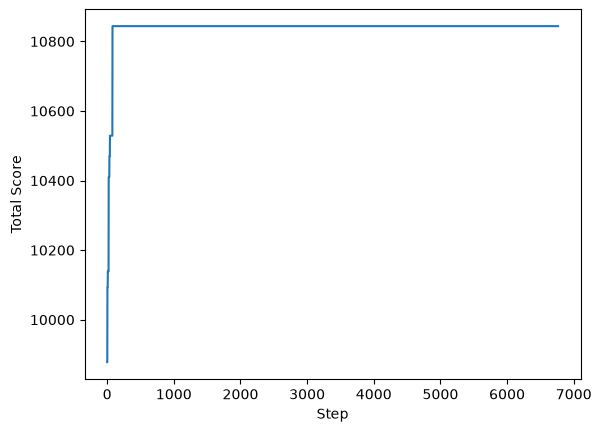

10844.0
[1 0 0 1 1 0 1 0 0 0 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 0 0
 0 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 0 1 1 0 0 1 1
 0 1 0 0 1 0 1 1 0 0 1 1 0 0 0 0]
[1499. 1096. 1799. 1700. 2151.]


In [45]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

# improve function and make some changeable parameters for varitant
**What changed:** now instead of random result fully the `CapuchinoAssassino` function now has current to pick a change_device number to randomly switch and noise so that efficiency score can switch more so that it can change more model at a time

In [ ]:
def CapuchinoAssassino(utilities, demands, capacities, current=None, noise=0, change_device=1):
    if current is None:
        result=np.random.randint(0,2,size=len(utilities))
    else:
        result=current.copy()
        j=np.random.choice(len(utilities), size=change_device, replace=False)
        result[j]=1-result[j]
    usage=demands @ result
    
    if not np.all(usage <= capacities):
        eff=utilities/((demands/capacities[:,None]).sum(axis=0)+1e-9)
        if noise>0:
            eff=eff*np.random.uniform(1-noise,1+noise,len(eff))
        order=np.argsort(-eff)
        for k in order[::-1]:
            if np.all(usage <= capacities):
                break
            if result[k]==1:
                result[k]=0
                usage=usage-demands[:,k]
        for k in order:
            if result[k]==0 and np.all(usage+demands[:,k] <= capacities):
                result[k]=1
                usage=usage+demands[:,k]
    brainrot=utilities @ result
    brain_cap=demands @ result
    return brainrot,brain_cap,result

def SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=None):
    if brainrot>=bestie:
        bestie = brainrot
        bestie_res = result

    return bestie,bestie_res
    
def league_of_legends(n, m, utilities, demands, capacities, noise=0, change_device=1):
    log=[]
    for lol in range(1, 6767):
        if lol==1:
            brainrot,brain_cap,result= CapuchinoAssassino(utilities, demands,capacities)
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=np.zeros(n, dtype=int))
        else:
            brainrot,brain_cap,result= CapuchinoAssassino(utilities, demands,capacities,current=bestie_res,noise=noise,change_device=change_device)
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=bestie,bestie_res=bestie_res)
            
        log.append({'lol':lol,'score':bestie})
    
    return bestie,bestie_res,log

## Evaluation between 2 variants after 30 runs (n90, m5)

Each variants was run 30 times with the same 6,766 steps and the line plot below illustrates the mean of chosen utility score while the box plot plot the varies between final results in 30 runs.

| Metric | Determistic variant | More random choice variant |
|---|---|---|
| Mean final utility | 10,953 | 11,190 |
| Mean time per run | 0.51 s | 0.68 s |

**Comparision:**

1. **More random choice variant have slightly mean higher utility score than Determistic:** The More random choice variant have approximately 200 higher mean utility score than Determistic because determistic only chose once model to change with no change to noise meanwhile the more random choice variant picks 5 models instead once and set noise to 0.3 so that it can make more difference variant and the noise can make efficiency score to widance more so that similar utility score can be scored more difference making new changes to the model choice
2. **Determistic variant took less time to complete than repair function but need more steps to find best score:** Because Determistic variant only chose once model per steps, it will required only 0.51s compared to 0.68s to the random choice of picking 5 models to change per step although the random choice can reach greater result in fewer steps
3. **The randomised variants give more reliable higher result:** As can be seen from the box plot, the randomised variants can provides not only much more stable change of results in each run but also the worst result of randomised variants are still higher than the best in Determistic variant

**Verdict:**
- chose Determistic variant if: want to utilise the least time and fewest complex possible in order to find the best result although it may required more steps to reach for better result as the variant only chose one model to change at a time
- chose More random choice variant if: needs to reach better utilised result scores in fewer step and a more stable but higher result score. However, when run in higher number of steps, the function can only barely improves in later steps compare to first few steps

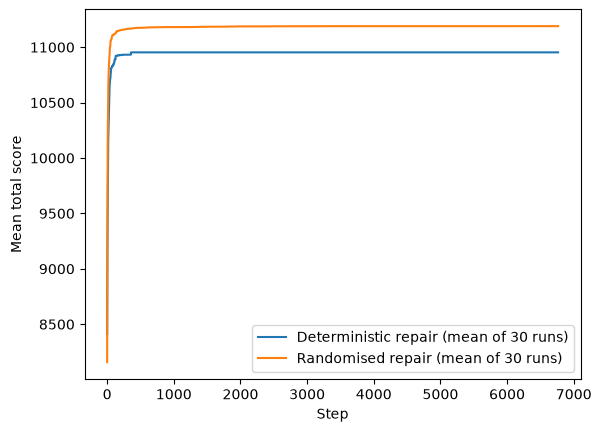

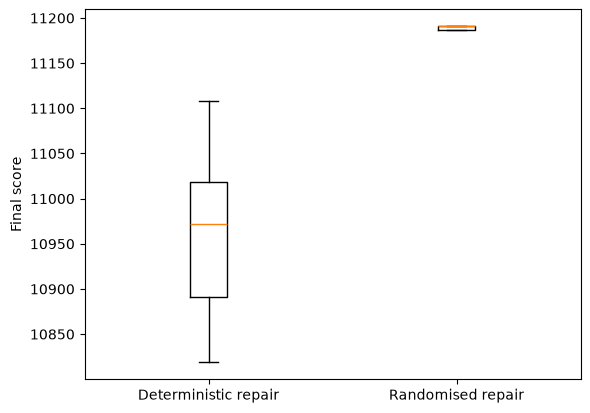

Deterministic repair took 0.51s, mean final score 10953, std 87
Randomised repair took 0.68s, mean final score 11190, std 2


In [48]:
if __name__ == "__main__":
    sample_file = "multi_resource_n90_m5 (1).txt"
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        time_determisticfunc=[]
        time_randomfunc=[]
        logs_deter=[]
        logs_random=[]
        for run in range(30):
            start = time.time()
            bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
            time_determisticfunc.append(time.time()-start)
            logs_deter.append([lmao['score'] for lmao in log])

            start = time.time()
            bestie2,bestie_res2,log2=league_of_legends(n, m, utilities, demands, capacities, noise=0.3,change_device=3)
            time_randomfunc.append(time.time()-start)
            logs_random.append([lmao['score'] for lmao in log2])

        plt.plot(np.mean(logs_deter,axis=0),label="Deterministic repair (mean of 30 runs)")
        plt.plot(np.mean(logs_random,axis=0),label="Randomised repair (mean of 30 runs)")
        plt.xlabel("Step")
        plt.ylabel("Mean total score")
        plt.legend()
        plt.show()

        final_deter=[l[-1] for l in logs_deter]
        final_random=[l[-1] for l in logs_random]
        plt.boxplot([final_deter, final_random])
        plt.xticks([1,2],["Deterministic repair","Randomised repair"])
        plt.ylabel("Final score")
        plt.show()

        print(f"Deterministic repair took {np.mean(time_determisticfunc):.2f}s, mean final score {np.mean(final_deter):.0f}, std {np.std(final_deter):.0f}")
        print(f"Randomised repair took {np.mean(time_randomfunc):.2f}s, mean final score {np.mean(final_random):.0f}, std {np.std(final_random):.0f}")

    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")